>Feature engineering transforms raw transaction data into behavioral signals that help reveal abnormal patterns. In anomaly detection, the quality of features often matters more than the choice of model.
>Effective fraud detection focuses on behavioral rather than static features, with time playing a central role in capturing changes in activity. At the same time, care must be taken to avoid information leakage, as it can lead to misleading model performance.

# PaySim

## Time-based Transaction Count Features

In [ ]:
import pandas as pd

paysim = pd.read_csv("../data/raw/paysim.csv")

In [ ]:
# sort step feature
paysim = paysim.sort_values(["nameOrig", "step"]).reset_index(drop=True)

In [ ]:
paysim.groupby("nameOrig")["step"].is_monotonic_increasing.all()

np.True_

In [ ]:
import numpy as np

groups = paysim.groupby("nameOrig").indices
steps_all = paysim["step"].values

windows = {
    "24h": 24,
    "72h": 72,
    "7d": 168
}

for name, window in windows.items():
    tx_count = np.zeros(len(paysim), dtype=np.int32)

    for idx in groups.values():
        steps = steps_all[idx]
        j = 0

        for i in range(len(steps)):
            while steps[j] < steps[i] - window:
                j += 1
            tx_count[idx[i]] = i - j + 1

    paysim[f"tx_count_last_{name}"] = tx_count


In [ ]:
paysim["tx_count_last_24h"].isna().sum()

np.int64(0)

In [ ]:
paysim["tx_count_last_24h"].describe()


,tx_count_last_24h
count,6.362620e+06
mean,1.000181e+00
std,1.345454e-02
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,1.000000e+00
max,2.000000e+00


In [ ]:
paysim["tx_count_last_72h"].isna().sum()

np.int64(0)

In [ ]:
paysim["tx_count_last_72h"].describe()

,tx_count_last_72h
count,6.362620e+06
mean,1.000440e+00
std,2.096200e-02
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,1.000000e+00
max,2.000000e+00


In [ ]:
paysim["tx_count_last_7d"].isna().sum()

np.int64(0)

In [ ]:
paysim["tx_count_last_7d"].describe()


,tx_count_last_7d
count,6.362620e+06
mean,1.000882e+00
std,2.970701e-02
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,1.000000e+00
max,3.000000e+00


In [ ]:
paysim["tx_count_total_user"] = (
    paysim
    .groupby("nameOrig")["step"]
    .transform("count")
)

To capture short-term and mid-term behavioral patterns, several time-based transaction count features were engineered using sliding temporal windows. Specifically, the number of transactions performed by each user within the last 24 hours, 72 hours, and 7 days was computed based on the step variable, which represents elapsed hours in the PaySim simulation. These features aim to model bursty or unusually frequent transaction behavior, which is often indicative of fraudulent activity.

In addition, a global baseline feature (tx_count_total_user) was introduced to represent the total number of transactions performed by each user throughout the entire simulation. This feature provides contextual information about a user's overall activity level and allows the model to distinguish between inherently low-activity users and sudden deviations from typical behavior when combined with time-based counts.

## Time-based Transaction Amount Features

In [ ]:
amounts_all = paysim["amount"].values

In [ ]:
windows = {
    "24h": 24,
    "7d": 168
}

for name, window in windows.items():
    sum_amount = np.zeros(len(paysim), dtype=np.float32)

    for idx in groups.values():
        steps = steps_all[idx]
        amounts = amounts_all[idx]

        j = 0
        running_sum = 0.0

        for i in range(len(steps)):
            running_sum += amounts[i]

            while steps[j] < steps[i] - window:
                running_sum -= amounts[j]
                j += 1

            sum_amount[idx[i]] = running_sum

    paysim[f"sum_amount_last_{name}"] = sum_amount
    paysim[f"avg_amount_last_{name}"] = (
        sum_amount / paysim[f"tx_count_last_{name}"]
    )

In [ ]:
paysim[[
    "sum_amount_last_24h",
    "avg_amount_last_24h"
]].isna().sum()


,0
sum_amount_last_24h,0
avg_amount_last_24h,0


In [ ]:
paysim[[
    "sum_amount_last_24h",
    "avg_amount_last_24h"
]].describe()


,sum_amount_last_24h,avg_amount_last_24h
count,6.362620e+06,6.362620e+06
mean,1.799040e+05,1.798675e+05
std,5.947048e+05,5.944260e+05
min,0.000000e+00,0.000000e+00
25%,1.339283e+04,1.339203e+04
50%,7.489770e+04,7.488427e+04
75%,2.087495e+05,2.087176e+05
max,9.244552e+07,9.244552e+07


In [ ]:
paysim[[
    "sum_amount_last_7d",
    "avg_amount_last_7d"
]].isna().sum()


,0
sum_amount_last_7d,0
avg_amount_last_7d,0


In [ ]:
paysim[[
    "sum_amount_last_7d",
    "avg_amount_last_7d"
]].describe()


,sum_amount_last_7d,avg_amount_last_7d
count,6.362620e+06,6.362620e+06
mean,1.800258e+05,1.798618e+05
std,5.950166e+05,5.942920e+05
min,0.000000e+00,0.000000e+00
25%,1.340401e+04,1.339981e+04
50%,7.498725e+04,7.492885e+04
75%,2.088801e+05,2.087044e+05
max,9.244552e+07,9.244552e+07


To capture spending behavior over different time scales, time-based transaction amount features were created using sliding windows aligned with the PaySim simulation time. For each transaction, both the total and average transferred amounts were calculated per user over the past 24 hours and the past 7 days.

The 24-hour window is intended to capture short-term spending spikes that may signal sudden abnormal behavior, while the 7-day window provides a broader view of recent activity. The similar distribution observed across these features reflect the sparse transaction patterns in PaySim, highlighting the need to combine amount-based features with frequency-based singals for effective anomaly detection.

## Counterparty Interaction & Diversity Features


In [ ]:
dest_codes, dest_uniques = paysim["nameDest"].factorize()
dest_codes = dest_codes.astype(np.int32)


In [ ]:
def unique_dest_counts_per_user(
    steps,
    dest_codes,
    idx,
    window
):
    n = len(idx)
    out = np.zeros(n, dtype=np.int32)

    start = 0

    for i in range(n):
        current_step = steps[idx[i]]

        while steps[idx[start]] < current_step - window:
            start += 1

        seen = set()
        for k in range(start, i + 1):
            seen.add(dest_codes[idx[k]])

        out[i] = len(seen)

    return out


In [ ]:
windows = {
    "24h": 24,
    "72h": 72,
    "7d": 168
}

for name, window in windows.items():
    result = np.zeros(len(paysim), dtype=np.int32)

    for idx in groups.values():
        counts = unique_dest_counts_per_user(
            steps_all,
            dest_codes,
            idx,
            window
        )
        result[idx] = counts

    paysim[f"unique_dest_last_{name}"] = result


In [ ]:
paysim[[
    "unique_dest_last_24h",
    "unique_dest_last_72h",
    "unique_dest_last_7d"
]].isna().sum()


,0
unique_dest_last_24h,0
unique_dest_last_72h,0
unique_dest_last_7d,0


In [ ]:
paysim[[
    "unique_dest_last_24h",
    "unique_dest_last_72h",
    "unique_dest_last_7d"
]].describe()


,unique_dest_last_24h,unique_dest_last_72h,unique_dest_last_7d
count,6.362620e+06,6.362620e+06,6.362620e+06
mean,1.000181e+00,1.000440e+00,1.000882e+00
std,1.345454e-02,2.096200e-02,2.970701e-02
min,1.000000e+00,1.000000e+00,1.000000e+00
25%,1.000000e+00,1.000000e+00,1.000000e+00
50%,1.000000e+00,1.000000e+00,1.000000e+00
75%,1.000000e+00,1.000000e+00,1.000000e+00
max,2.000000e+00,2.000000e+00,3.000000e+00


Unique destination features quantify the diversity of counterparties a user interacts with over recent time windows. In typical user behavior, transactions are usually directed toward a small and stable set of recipients, resulting in low destination diversity even over longer periods. An increase in the number of unique destinations within short or medium time windows may indicate abnormal behavior, such as rapid fund dispersion or automated transaction patterns. These features capture interaction diversity independently of transaction volume and complement transaction count–based features by focusing on behavioral spread rather than frequency.

## Ratio-based Transaction Behavior Features



In [ ]:
eps = 1e-6  # safety

windows = ["24h", "72h", "7d"]

for w in windows:
    paysim[f"unique_dest_ratio_{w}"] = (
        paysim[f"unique_dest_last_{w}"] /
        (paysim[f"tx_count_last_{w}"] + eps)
    )


In [ ]:
paysim[[
    "unique_dest_ratio_24h",
    "unique_dest_ratio_72h",
    "unique_dest_ratio_7d"
]].describe()


,unique_dest_ratio_24h,unique_dest_ratio_72h,unique_dest_ratio_7d
count,6.362620e+06,6.362620e+06,6.362620e+06
mean,9.999990e-01,9.999990e-01,9.999990e-01
std,6.727271e-09,1.048099e-08,1.483879e-08
min,9.999990e-01,9.999990e-01,9.999990e-01
25%,9.999990e-01,9.999990e-01,9.999990e-01
50%,9.999990e-01,9.999990e-01,9.999990e-01
75%,9.999990e-01,9.999990e-01,9.999990e-01
max,9.999995e-01,9.999995e-01,9.999997e-01


>**Note:**  
Due to transaction sparsity in short time windows within PaySim, these ratio features exhibit extremely low variance and are therefore not expected to contribute significant predictive power. They are retained for completeness but may be excluded during feature selection.


## User-level Aggregate Transaction Behavior

In [ ]:
tx_count_total = paysim.groupby("nameOrig").size()

paysim["tx_count_total_user"] = paysim["nameOrig"].map(tx_count_total)

In [ ]:
unique_dest_total = paysim.groupby("nameOrig")["nameDest"].nunique()

paysim["unique_dest_total_user"] = paysim["nameOrig"].map(unique_dest_total)

In [ ]:
eps = 1e-6

paysim["unique_dest_ratio_total"] = (
    paysim["unique_dest_total_user"] /
    (paysim["tx_count_total_user"] + eps)
)

In [ ]:
paysim[[
    "tx_count_total_user",
    "unique_dest_total_user",
    "unique_dest_ratio_total"
]].describe()

,tx_count_total_user,unique_dest_total_user,unique_dest_ratio_total
count,6.362620e+06,6.362620e+06,6.362620e+06
mean,1.002932e+00,1.002932e+00,9.999990e-01
std,5.420031e-02,5.420031e-02,2.702765e-08
min,1.000000e+00,1.000000e+00,9.999990e-01
25%,1.000000e+00,1.000000e+00,9.999990e-01
50%,1.000000e+00,1.000000e+00,9.999990e-01
75%,1.000000e+00,1.000000e+00,9.999990e-01
max,3.000000e+00,3.000000e+00,9.999997e-01


>**Note:**  
Due to the highly sparse transaction patterns in the PaySim dataset, most users
perform only a single transaction across the entire simulation. As a result,
user-level aggregate count and destination ratio features exhibit extremely low
variance and are unlikely to provide meaningful discriminative signal. These
features were evaluated for completeness but are excluded from subsequent
modeling stages.


## Categorical Features

In [ ]:
type_dummies = pd.get_dummies(paysim["type"], prefix="type")
paysim = pd.concat([paysim, type_dummies], axis=1)

In [ ]:
paysim = paysim.drop(columns=["type"])


In [ ]:
paysim = paysim.drop(columns=["nameOrig"])


In [ ]:
paysim = paysim.drop(columns=["nameDest"])


Categorical Feature Handling

The dataset contains a small number of categorical features with different roles. The type feature represents the transaction category and carries important behavioral information. Since it has no natural order, it is encoded using one-hot encoding, and the original column is removed to avoid redundancy.

The nameOrig and nameDest features are high-cardinality identifiers rather than meaningful categories. Encoding them directly would introduce sparsity and overfitting. Instead, their information is captured through aggregated behavioral features such as rolling transaction counts, amounts, and counterparty diversity. After these features are created, the raw identifiers are dropped so the model focuses on behavioral patterns rather than specific accounts.

# CreditCard

In [19]:
import pandas as pd

creditcard = pd.read_csv("./creditcard.csv")

## Log Amount

In [20]:
import numpy as np

creditcard["log_amount"] = np.log1p(creditcard["Amount"])

In [21]:
creditcard[["Amount", "log_amount"]].describe()

,Amount,log_amount
count,284807.000000,284807.000000
mean,88.349619,3.152188
std,250.120109,1.656648
min,0.000000,0.000000
25%,5.600000,1.887070
50%,22.000000,3.135494
75%,77.165000,4.358822
max,25691.160000,10.153941


In [22]:
creditcard[["log_amount"]].isna().sum()

,0
log_amount,0


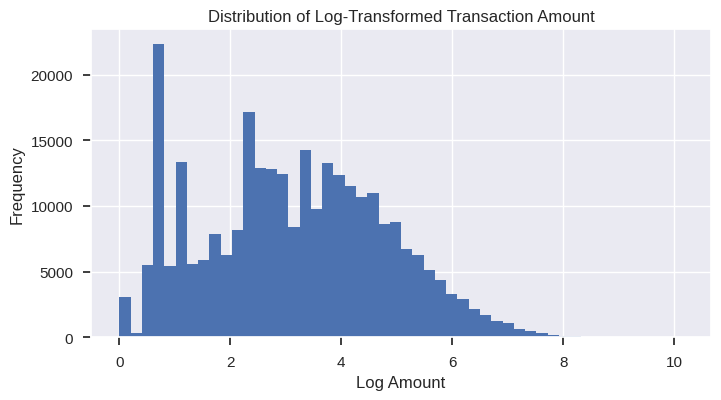

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.hist(creditcard["log_amount"], bins=50)

plt.title("Distribution of Log-Transformed Transaction Amount")

plt.xlabel("Log Amount")

plt.ylabel("Frequency")

plt.show()

Log Transformation of Transaction Amount

The original Amount feature exhibits a highly right-skewed distribution, with many low-value transactions and a relatively small number of very large payments. To reduce the influence of these extreme values while preserving the relative ordering of transaction amounts, a logarithmic transformation (log1p) was applied. As expected, the transformed feature compresses the long right tail and produces a more balanced numerical distribution without introducing missing values or data leakage. Although the transformed distribution is not perfectly normal, it provides a more stable representation for many machine learning algorithms. Both the original Amount and the derived log_amount features are retained for subsequent model training and feature selection.

Feature Engineering Considerations

Unlike the PaySim dataset, the Credit Card Fraud dataset provides very limited interpretable information for behavioral feature engineering. It does not include customer identifiers, merchant information, destination accounts, or real-world temporal attributes that would support user-level aggregation or transaction velocity features. In addition, the variables V1-V28 are anonymized principal components generated through PCA, meaning they already represent transformed feature combinations while preserving privacy. As a result, constructing additional behavioral or interaction-based features would require unsupported assumptions and could introduce artificial patterns into the data. Therefore, feature engineering was intentionally limited to a logarithmic transformation of the transaction amount, which improves the numerical representation of the original feature without altering its underlying information.